# 01 — Exploratory Data Analysis: RSNA Lung Opacity (chest X-ray, DICOM)

**Course modules used:** Day 5 (loading data), Day 6 (data-quality audit), Day 7 (EDA and visualisation),
Day 22 (leakage-safe splitting), brief step 1 (read DICOM).

**What this dataset actually is.** Downloaded as `rsna-pneumonia-detection-challenge`, this is the **2018 RSNA
Lung Opacity Detection** release: **26,684 chest X-ray DICOM files** and a label file with **30,227 rows** —
because a row is one *bounding box*, not one *image*. `Target = 1` means "a lung opacity is present". It is not
the 2022 relaunch (that one ships flat PNGs), and the label is the radiographic **sign**, not a pneumonia
diagnosis.

Two facts about this data get measured below rather than asserted:

1. the annotation file is finer-grained than the image file, which is a live leakage trap;
2. the de-identification applied to this release destroyed patient linkage, so "patient-level split" means
   something weaker here than it does in real clinical data.

> **For education only. Not for clinical use.**

In [1]:
from pathlib import Path
import os, sys, json, platform

IN_COLAB = "google.colab" in sys.modules
REPO_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))
(REPO_ROOT / "results" / "plots").mkdir(parents=True, exist_ok=True)
print("repo root :", REPO_ROOT)
print("runtime   :", "Google Colab" if IN_COLAB else "local (" + platform.python_version() + ")")

repo root : C:\Users\kumar\Documents\Qoder\2026-10-22\410be6bc\AIML-02-medical-imaging
runtime   : local (3.13.1)


In [2]:
DATA_ROOT = Path(os.getenv("RSNA_DATA_DIR") or (REPO_ROOT / "data" / "raw" / "rsna"))
if not DATA_ROOT.is_dir():
    DATA_ROOT = REPO_ROOT / "data" / "raw"


def _find(*names):
    for name in names:
        hits = sorted(DATA_ROOT.rglob(name))
        if hits:
            return hits[0]
    return None


LABELS_CSV = _find("stage_2_train_labels.csv", "train_labels.csv")
if LABELS_CSV is None:
    raise SystemExit(
        f"No label CSV under {DATA_ROOT}. Download and unzip with:\n"
        "  kaggle competitions download -c rsna-pneumonia-detection-challenge -p data/raw/rsna\n"
        "  python -c \"import zipfile; zipfile.ZipFile('stage_2_train_labels.csv.zip').extractall('data/raw/rsna')\"\n"
        "Looked for: stage_2_train_labels.csv, train_labels.csv"
    )

DATA_DIR = LABELS_CSV.parent
CLASS_CSV = _find("stage_2_detailed_class_info.csv")
HEADER_CSV = DATA_DIR / "dicom_headers.csv"
IMAGES_DIR = next((d for d in [DATA_DIR / "stage_2_train_images", DATA_DIR / "train_images", DATA_DIR]
                   if d.is_dir() and any(d.glob("*.dcm"))), None)

if IMAGES_DIR is None:
    raise SystemExit(f"No .dcm files found under {DATA_DIR} — the image archive is still zipped.")

n_dcm = sum(1 for _ in IMAGES_DIR.glob("*.dcm"))
print("label file  :", LABELS_CSV.name)
print("class file  :", CLASS_CSV.name if CLASS_CSV else "absent")
print("images dir  :", IMAGES_DIR, f"({n_dcm:,} .dcm files)")
print("header cache:", HEADER_CSV.name if HEADER_CSV.is_file()
      else "absent — run tools/scan_dicom_headers.py (see section 4)")

label file  : stage_2_train_labels.csv
class file  : stage_2_detailed_class_info.csv
images dir  : C:\Users\kumar\Documents\Qoder\2026-10-22\410be6bc\AIML-02-medical-imaging\data\raw\rsna\stage_2_train_images (26,684 .dcm files)
header cache: dicom_headers.csv


## 1 · Load and audit the tabular data

Course **Day 5** (loading and manipulating) and **Day 6** (data quality). Before modelling anything, find out what
you actually have: shape, dtypes, missing values, duplicates, and whether the ID columns mean what you assume.

In [3]:
import pandas as pd
import numpy as np

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

# Load the label file. Read the next cell before trusting the word "row".
ann = pd.read_csv(LABELS_CSV)

# stage_2 labels key images on patientId; the 2022 layout keys on SeriesInstanceUID.
IMG_ID = "patientId" if "patientId" in ann.columns else "SeriesInstanceUID"
print(f"columns        : {list(ann.columns)}")
print(f"image key used : {IMG_ID}")
ann.head(8)

columns        : ['patientId', 'x', 'y', 'width', 'height', 'Target']
image key used : patientId


,patientId,x,y,width,height,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1
5,00436515-870c-4b36-a041-de91049b9ab4,562.0,152.0,256.0,453.0,1
6,00569f44-917d-4c86-a842-81832af98c30,NaN,NaN,NaN,NaN,0
7,006cec2e-6ce2-4549-bffa-eadfcd1e9970,NaN,NaN,NaN,NaN,0


In [4]:
ann.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30227 entries, 0 to 30226
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   patientId  30227 non-null  object 
 1   x          9555 non-null   float64
 2   y          9555 non-null   float64
 3   width      9555 non-null   float64
 4   height     9555 non-null   float64
 5   Target     30227 non-null  int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 1.4+ MB


In [5]:
audit = pd.DataFrame({
    "dtype": ann.dtypes.astype(str),
    "non_null": ann.notna().sum(),
    "null": ann.isna().sum(),
    "null_pct": (ann.isna().mean() * 100).round(2),
    "n_unique": ann.nunique(),
}).sort_values("null", ascending=False)
print(audit)

n_images_in_csv = int(ann[IMG_ID].nunique())
print(f"\nannotation rows              : {len(ann):,}")
print(f"distinct {IMG_ID:<12}: {n_images_in_csv:,}   <- the real number of pictures")
print(f"fully duplicated rows        : {int(ann.duplicated().sum()):,}")
print(f"rows carrying a bounding box : {int(ann['x'].notna().sum()):,}")
print(f"\nratio rows / images = {len(ann) / n_images_in_csv:.3f}  "
      "(1.000 would mean one row per picture)")

             dtype  non_null   null  null_pct  n_unique
x          float64      9555  20672     68.39       748
y          float64      9555  20672     68.39       726
height     float64      9555  20672     68.39       725
width      float64      9555  20672     68.39       351
patientId   object     30227      0      0.00     26684
Target       int64     30227      0      0.00         2

annotation rows              : 30,227
distinct patientId   : 26,684   <- the real number of pictures
fully duplicated rows        : 0
rows carrying a bounding box : 9,555

ratio rows / images = 1.133  (1.000 would mean one row per picture)


In [6]:
# The trap in this file: rows are not pictures. demonstrated on real rows, not in prose.
rows_per_image = ann[IMG_ID].value_counts()
print("how many annotation rows an image gets:")
print(rows_per_image.value_counts().sort_index().to_string())

example = rows_per_image[rows_per_image > 1].index[0]
print(f"\nexample image {example} — {rows_per_image[example]} rows:")
ann[ann[IMG_ID] == example].to_string()

how many annotation rows an image gets:
count
1    23286
2     3266
3      119
4       13

example image 7d674c82-5501-4730-92c5-d241fd6911e7 — 4 rows:


'                                  patientId      x      y  width  height  Target\n12251  7d674c82-5501-4730-92c5-d241fd6911e7  358.0  320.0  159.0   186.0       1\n12252  7d674c82-5501-4730-92c5-d241fd6911e7  283.0  528.0  197.0   314.0       1\n12253  7d674c82-5501-4730-92c5-d241fd6911e7  718.0  573.0  133.0   227.0       1\n12254  7d674c82-5501-4730-92c5-d241fd6911e7  658.0  315.0  164.0   203.0       1'

### Class info, and the header cache

`stage_2_detailed_class_info.csv` carries a three-way radiologist class. `tools/scan_dicom_headers.py`
(previously run) reads every DICOM tag straight off disk — that is the only place the *real* patient
grouping could live.

In [7]:
class_info = None
class_unique = None
if CLASS_CSV is not None:
    class_info = pd.read_csv(CLASS_CSV)
    print(f"{CLASS_CSV.name}: rows={len(class_info):,}, distinct {IMG_ID}={class_info[IMG_ID].nunique():,}")
    print(class_info["class"].value_counts().to_string())
    # This file is per-box as well, so it must be collapsed before any join. Joining it raw silently
    # duplicates images and reintroduces the very leak section 2 measures.
    class_unique = class_info.drop_duplicates(IMG_ID).rename(columns={IMG_ID: "patient_id"})[["patient_id", "class"]]
    assert class_unique["patient_id"].is_unique

hdr = None
if HEADER_CSV.is_file():
    hdr = pd.read_csv(HEADER_CSV, dtype=str)
    print(f"\n{HEADER_CSV.name}: {len(hdr):,} DICOM files read from disk")
else:
    print("\nNo header cache yet — run:")
    print("  python tools/scan_dicom_headers.py --images data/raw/rsna/stage_2_train_images \\")
    print("      --out data/raw/rsna/dicom_headers.csv")

stage_2_detailed_class_info.csv: rows=30,227, distinct patientId=26,684
class
No Lung Opacity / Not Normal    11821
Lung Opacity                     9555
Normal                           8851



dicom_headers.csv: 26,684 DICOM files read from disk


In [8]:
# Does any patient have more than one image? Answer it from the tags, not from the CSV's column name.
if hdr is not None:
    per_patient = hdr["PatientID"].value_counts()
    print(f"DICOM files                    : {len(hdr):,}")
    print(f"distinct PatientID inside them : {hdr['PatientID'].nunique():,}")
    print(f"distinct StudyInstanceUID      : {hdr['StudyInstanceUID'].nunique():,}")
    print(f"files sharing a PatientID      : {int((per_patient > 1).sum()):,}")
    print(f"missing PatientID              : {int(hdr['PatientID'].isna().sum()):,}")
else:
    print("Skipping: no header cache.")

DICOM files                    : 26,684
distinct PatientID inside them : 26,684
distinct StudyInstanceUID      : 26,684
files sharing a PatientID      : 0
missing PatientID              : 0


In [9]:
# Collapse the annotation file to exactly one row per image, keeping label + box count.
images = (
    ann.groupby(IMG_ID, as_index=False)
       .agg(label=("Target", "max"), n_boxes=("x", "count"))
       .rename(columns={IMG_ID: "patient_id"})
)

if class_unique is not None:
    before = len(images)
    images = images.merge(class_unique, on="patient_id", how="left", validate="one_to_one")
    assert len(images) == before, "merge changed the row count"

# Two path columns on purpose. dicom_rel is stored in the CSVs and survives a move to another machine;
# dicom_path is the absolute file this kernel reads right now.
images["dicom_rel"] = [f"{IMAGES_DIR.name}/{pid}.dcm" for pid in images["patient_id"]]
images["dicom_path"] = [str(IMAGES_DIR / f"{pid}.dcm") for pid in images["patient_id"]]
absent = int((~images["dicom_path"].map(lambda p: Path(p).is_file())).sum())
images = images[images["dicom_path"].map(lambda p: Path(p).is_file())].reset_index(drop=True)

print(f"images in label file : {len(images) + absent:,}")
print(f"with a .dcm on disk  : {len(images):,}   (missing {absent:,})")
print(f"distinct patient ids : {images['patient_id'].nunique():,}")
print(f"opacity boxes total  : {int(images['n_boxes'].sum()):,}")
assert images["patient_id"].is_unique, "the image table must be one row per picture"
print("assertion passed: one row per picture")
images[["patient_id", "label", "n_boxes", "class", "dicom_rel"]].head()

images in label file : 26,684
with a .dcm on disk  : 26,684   (missing 0)
distinct patient ids : 26,684
opacity boxes total  : 9,555
assertion passed: one row per picture


,patient_id,label,n_boxes,class,dicom_rel
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,0,0,No Lung Opacity / Not Normal,stage_2_train_images/0004cfab-14fd-4e49-80ba-6...
1,000924cf-0f8d-42bd-9158-1af53881a557,0,0,Normal,stage_2_train_images/000924cf-0f8d-42bd-9158-1...
2,000db696-cf54-4385-b10b-6b16fbb3f985,1,2,Lung Opacity,stage_2_train_images/000db696-cf54-4385-b10b-6...
3,000fe35a-2649-43d4-b027-e67796d412e0,1,2,Lung Opacity,stage_2_train_images/000fe35a-2649-43d4-b027-e...
4,001031d9-f904-4a23-b3e5-2c088acd19c6,1,2,Lung Opacity,stage_2_train_images/001031d9-f904-4a23-b3e5-2...


## 2 — The two granularities in this file, and which one to split on

There are 30,227 label rows and 26,684 pictures. Whatever you shuffle, you must shuffle the **pictures**.
Splitting rows sounds identical and is not.

In [10]:
films = images.groupby("patient_id").size()
print("images per patient, as recovered from the DICOM PatientID tag:")
print(films.value_counts().to_string())

boxes = images["n_boxes"]
print("\nopacity boxes per positive image:")
print(boxes[boxes > 0].value_counts().sort_index().head(12).to_string())
print(f"\npositive images with >=1 box : {(boxes > 0).sum():,}")
print(f"max boxes on a single image  : {int(boxes.max())}")

images per patient, as recovered from the DICOM PatientID tag:
1    26684

opacity boxes per positive image:
n_boxes
1    2614
2    3266
3     119
4      13

positive images with >=1 box : 6,012
max boxes on a single image  : 4


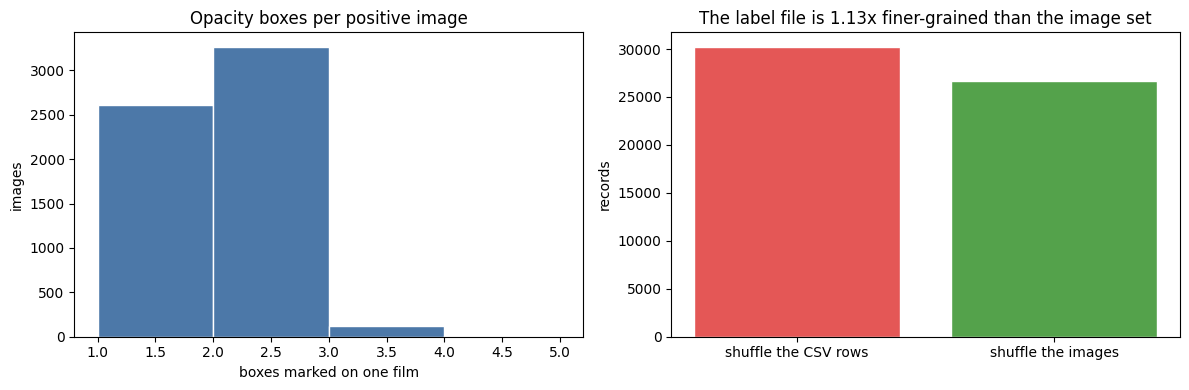

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(boxes[boxes > 0], bins=range(1, int(boxes.max()) + 2), color="#4c78a8", edgecolor="white")
axes[0].set_title("Opacity boxes per positive image")
axes[0].set_xlabel("boxes marked on one film")
axes[0].set_ylabel("images")

row_ratio = len(ann) / len(images)
axes[1].bar(["shuffle the CSV rows", "shuffle the images"], [len(ann), len(images)],
            color=["#e45756", "#54a24b"], edgecolor="white")
axes[1].set_ylabel("records")
axes[1].set_title(f"The label file is {row_ratio:.2f}x finer-grained than the image set")
fig.tight_layout()
fig.savefig(REPO_ROOT / "results" / "plots" / "eda_row_vs_image_granularity.png", dpi=130)
plt.show()

In [12]:
# Measure the leak that is actually reachable here: shuffling label ROWS puts the same picture in both folds.
rng = np.random.default_rng(0)
mask = rng.random(len(ann)) < 0.7
naive_tr, naive_te = ann[mask], ann[~mask]
shared = set(naive_tr[IMG_ID]) & set(naive_te[IMG_ID])
leaked_rows = int(naive_te[IMG_ID].isin(shared).sum())
leak_pct = leaked_rows / max(len(naive_te), 1) * 100

print("NAIVE split on annotation rows")
print(f"  images present in BOTH folds      : {len(shared):,} of {len(images):,}")
print(f"  test rows whose image was in train: {leaked_rows:,} of {len(naive_te):,}  ({leak_pct:.1f}%)")

# Same random seed, done on the one-row-per-image table.
mask2 = rng.random(len(images)) < 0.7
img_tr, img_te = images[mask2], images[~mask2]
clean_overlap = len(set(img_tr["patient_id"]) & set(img_te["patient_id"]))
print("\nSPLIT on images")
print(f"  images present in both folds      : {clean_overlap:,}")

NAIVE split on annotation rows
  images present in BOTH folds      : 1,499 of 26,684
  test rows whose image was in train: 1,524 of 9,069  (16.8%)

SPLIT on images
  images present in both folds      : 0


> **Write this down for the viva.** That first percentage is how much of your test set a model would have
> already *seen the exact pixels of*. Splitting the image table removes it completely.
>
> And be honest about the second thing section 1 found: every file in this release carries its own unique
> `PatientID`, so within-patient leakage cannot occur here *even in principle*. That is a property of RSNA's
> de-identification, not evidence that row-level splitting is safe — on LIDC-IDRI or any real archive, one
> patient contributes many films and the same guard is what saves you.

## 3 · Label distribution and class balance

In [13]:
by_class = images.groupby("label").agg(
    images=("label", "size"), patients=("patient_id", "nunique"), boxes=("n_boxes", "sum"))
by_class["image_share_pct"] = (by_class["images"] / by_class["images"].sum() * 100).round(2)
by_class.index = by_class.index.map({0: "no lung opacity", 1: "lung opacity"})
print(by_class)

pos, neg = int(by_class.loc["lung opacity", "images"]), int(by_class.loc["no lung opacity", "images"])
print(f"\nimbalance ratio (neg:pos) = {neg / max(pos, 1):.2f} : 1")
print("=> accuracy is a misleading headline metric here. Report AUROC, sensitivity, specificity.")
print(f"=> predicting 'no opacity' for everything scores {neg / (neg + pos) * 100:.1f}% accuracy and finds nothing.")

                 images  patients  boxes  image_share_pct
label                                                    
no lung opacity   20672     20672      0            77.47
lung opacity       6012      6012   9555            22.53

imbalance ratio (neg:pos) = 3.44 : 1
=> accuracy is a misleading headline metric here. Report AUROC, sensitivity, specificity.
=> predicting 'no opacity' for everything scores 77.5% accuracy and finds nothing.


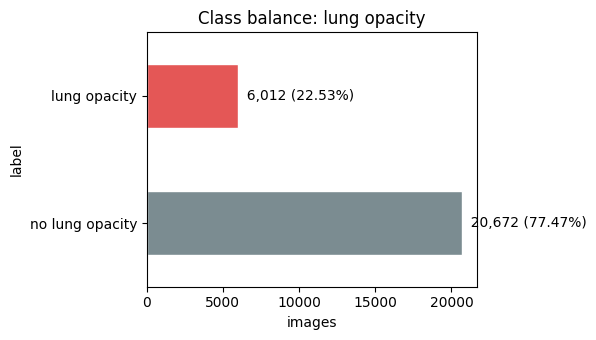

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.5))
by_class["images"].plot.barh(ax=ax, color=["#7b8c91", "#e45756"], edgecolor="white", legend=False)
ax.set_xlabel("images")
ax.set_title("Class balance: lung opacity")
for i, (value, share) in enumerate(zip(by_class["images"], by_class["image_share_pct"])):
    ax.text(value, i, f"  {value:,} ({share}%)", va="center")
fig.tight_layout()
fig.savefig(REPO_ROOT / "results" / "plots" / "eda_class_balance.png", dpi=130)
plt.show()

In [15]:
if class_info is None:
    print("No class info file in this download.")
else:
    print(class_info["class"].value_counts().to_string())
    # images already carries `class` (joined in section 1), so no re-merge here.
    print("\nTarget vs the radiologist class (one row per image):")
    print(pd.crosstab(images["label"], images["class"]))
    print("\n=> binary Target == 1 is exactly class 'Lung Opacity'. Three clinical classes collapse into two")
    print("   model classes. That collapse is a label-policy decision and belongs in dataset_card.md,")
    print("   not buried in a notebook - 'no opacity' and 'a different abnormality' are not the same thing.")
    other = int((images["class"] == "No Lung Opacity / Not Normal").sum())
    negatives = int((images["label"] == 0).sum())
    print(f"=> {other:,} images are labelled 0 because of some OTHER abnormality, not because the chest is")
    print(f"   normal. The negative class is heterogeneous: {other / max(negatives, 1) * 100:.1f}% of every")
    print(f"   negative image ({other:,} of {negatives:,}) is 'abnormal, but not opacity'.")

class
No Lung Opacity / Not Normal    11821
Lung Opacity                     9555
Normal                           8851

Target vs the radiologist class (one row per image):
class  Lung Opacity  No Lung Opacity / Not Normal  Normal
label                                                    
0                 0                         11821    8851
1              6012                             0       0

=> binary Target == 1 is exactly class 'Lung Opacity'. Three clinical classes collapse into two
   model classes. That collapse is a label-policy decision and belongs in dataset_card.md,
   not buried in a notebook - 'no opacity' and 'a different abnormality' are not the same thing.
=> 11,821 images are labelled 0 because of some OTHER abnormality, not because the chest is
   normal. The negative class is heterogeneous: 57.2% of every
   negative image (11,821 of 20,672) is 'abnormal, but not opacity'.


### Demographics recovered from the DICOM tags

The label CSV has no demographics, so this is the part that decides whether the fairness slice in Phase 3 is
possible at all. Age and sex are present on **every** file. They are also the most tempting shortcut in the
dataset: lung opacity correlates with age, so a model can score well by predicting demographics instead of
pathology.

In [16]:
if hdr is None:
    print("No header cache - demographics unavailable.")
else:
    tags = hdr[["file_id", "PatientSex", "PatientAge"]].rename(columns={"file_id": "patient_id"})
    images = images.merge(tags, on="patient_id", how="left", validate="one_to_one")
    images["age"] = pd.to_numeric(images["PatientAge"], errors="coerce")

    print(f"sex populated : {images['PatientSex'].notna().sum():,} / {len(images):,}")
    print(f"age populated : {images['age'].notna().sum():,} / {len(images):,}")
    print("\nsex      :", images["PatientSex"].value_counts(dropna=False).to_dict())
    print(f"age      : min={images['age'].min():.0f}  median={images['age'].median():.0f}  "
          f"max={images['age'].max():.0f}  mean={images['age'].mean():.1f}")

    implausible = images[(images["age"] < 1) | (images["age"] > 110)]
    print(f"\nIMPLAUSIBLE AGE: {len(implausible):,} images carry an age outside 1-110 "
          f"(max observed {images['age'].max():.0f}).")
    print("This is a source data error, not a preprocessing bug. Two honest options: drop those rows, or keep")
    print("them and never use age as a model input. This project keeps the images - throwing away a scan over a")
    print("metadata typo is worse than not trusting the metadata - and records the defect here.")

    print("\nopacity prevalence by sex:")
    print(images.groupby("PatientSex")["label"].agg(images="size", positives="sum",
          prevalence_pct=lambda s: round(s.mean() * 100, 2)).to_string())

    band = pd.cut(images["age"].clip(upper=110), [0, 40, 60, 80, 111],
                  labels=["<40", "40-59", "60-79", "80-110"])
    print("\nopacity prevalence by age band (ages clipped at 110 so the typo rows do not form their own band):")
    print(images.groupby(band, observed=True)["label"].agg(images="size", positives="sum",
          prevalence_pct=lambda s: round(s.mean() * 100, 2)).to_string())

    print("\n=> Prevalence moves by only a couple of points across sex and age, so demographics are not a")
    print("   strong marginal signal in THIS release - but that is a property of the labels, not a guarantee.")
    print("   The classifier sees pixels only; age and sex are carried for the Phase 3 slice audit, never as inputs.")

sex populated : 26,684 / 26,684
age populated : 26,684 / 26,684

sex      : {'M': 15166, 'F': 11518}
age      : min=1  median=49  max=155  mean=47.0

IMPLAUSIBLE AGE: 5 images carry an age outside 1-110 (max observed 155).
This is a source data error, not a preprocessing bug. Two honest options: drop those rows, or keep
them and never use age as a model input. This project keeps the images - throwing away a scan over a
metadata typo is worse than not trusting the metadata - and records the defect here.

opacity prevalence by sex:
            images  positives  prevalence_pct
PatientSex                                   
F            11518       2502           21.72
M            15166       3510           23.14

opacity prevalence by age band (ages clipped at 110 so the typo rows do not form their own band):
        images  positives  prevalence_pct
age                                      
<40       9044       2306           25.50
40-59    11667       2451           21.01
60-79     573

## 4 · Reading the DICOM files (project brief, step 1)

A DICOM file is a metadata header plus a pixel array. The header decides how those integers become a visible image:
`RescaleSlope` / `RescaleIntercept` turn stored values into real intensities, and `WindowCenter` / `WindowWidth`
decide which intensity band maps to black-through-white. Skip windowing and you can feed the network a picture no
radiologist would recognise.

In [17]:
from src.data.dicom_io import (
    WINDOW_CENTRE_DEFAULT, WINDOW_WIDTH_DEFAULT, describe, read_study,
    to_uint8, window_centre, window_width,
)

if hdr is not None:
    print(f"Across all {len(hdr):,} files")
    for col in ("Modality", "PatientSex", "PatientAge", "BodyPartExamined", "BitsAllocated"):
        print(f"  {col:<18}: {int(hdr[col].notna().sum()):,} populated -> "
              f"{hdr[col].dropna().unique()[:3].tolist()}")
    for col in ("Manufacturer", "ImageType", "PatientPosition", "WindowCenter", "WindowWidth"):
        print(f"  {col:<18}: {int(hdr[col].notna().sum()):,} populated")
    print(f"  StudyDate         : {hdr['StudyDate'].dropna().unique()[:1].tolist()} (a placeholder, not a real date)")
    print(f"  Rows x Columns    : {(hdr['Rows'] + 'x' + hdr['Columns']).value_counts().head(2).to_dict()}")
    print("""
Read straight off the envelope: SOP Class 1.2.840.10008.5.1.4.1.1.7 is Secondary Capture, pixels are 8-bit,
and Manufacturer / ImageType / PatientPosition / WindowCenter are all empty. A scanner writes those. A
conversion tool does not - which is exactly what RSNA documents having done. So these are real .dcm files
that Orthanc will happily accept, wrapping an already-display-encoded 8-bit render, not raw detector data.""")

sample_paths = images["dicom_path"].drop_duplicates().head(6).tolist()
rows = []
for path in sample_paths:
    try:
        rows.append(describe(read_study(path)))
    except Exception as exc:
        rows.append({"error": str(exc), "path": path})
pd.DataFrame(rows)

Across all 26,684 files
  Modality          : 26,684 populated -> ['CR']
  PatientSex        : 26,684 populated -> ['F', 'M']
  PatientAge        : 26,684 populated -> ['51', '19', '25']
  BodyPartExamined  : 26,684 populated -> ['CHEST']
  BitsAllocated     : 26,684 populated -> ['8']
  Manufacturer      : 0 populated
  ImageType         : 0 populated
  PatientPosition   : 0 populated
  WindowCenter      : 0 populated
  WindowWidth       : 0 populated
  StudyDate         : ['19010101'] (a placeholder, not a real date)
  Rows x Columns    : {'1024x1024': 26684}

Read straight off the envelope: SOP Class 1.2.840.10008.5.1.4.1.1.7 is Secondary Capture, pixels are 8-bit,
and Manufacturer / ImageType / PatientPosition / WindowCenter are all empty. A scanner writes those. A
conversion tool does not - which is exactly what RSNA documents having done. So these are real .dcm files
that Orthanc will happily accept, wrapping an already-display-encoded 8-bit render, not raw detector data.


,sop_class_uid,patient_id,study_instance_uid,modality,rows,columns,bits_allocated,photometric_interpretation,pixel_spacing,window_center,window_width,patient_position
0,1.2.840.10008.5.1.4.1.1.7,0004cfab-14fd-4e49-80ba-63a80b6bddd6,1.2.276.0.7230010.3.1.2.8323329.28530.15178744...,CR,1024,1024,8,MONOCHROME2,"[0.14300000000000002, 0.14300000000000002]",None,None,None
1,1.2.840.10008.5.1.4.1.1.7,000924cf-0f8d-42bd-9158-1af53881a557,1.2.276.0.7230010.3.1.2.8323329.20023.15178744...,CR,1024,1024,8,MONOCHROME2,"[0.139, 0.139]",None,None,None
2,1.2.840.10008.5.1.4.1.1.7,000db696-cf54-4385-b10b-6b16fbb3f985,1.2.276.0.7230010.3.1.2.8323329.4475.151787430...,CR,1024,1024,8,MONOCHROME2,"[0.168, 0.168]",None,None,None
3,1.2.840.10008.5.1.4.1.1.7,000fe35a-2649-43d4-b027-e67796d412e0,1.2.276.0.7230010.3.1.2.8323329.25090.15178744...,CR,1024,1024,8,MONOCHROME2,"[0.171, 0.171]",None,None,None
4,1.2.840.10008.5.1.4.1.1.7,001031d9-f904-4a23-b3e5-2c088acd19c6,1.2.276.0.7230010.3.1.2.8323329.9271.151787434...,CR,1024,1024,8,MONOCHROME2,"[0.139, 0.139]",None,None,None
5,1.2.840.10008.5.1.4.1.1.7,0010f549-b242-4e94-87a8-57d79de215fc,1.2.276.0.7230010.3.1.2.8323329.8679.151787433...,CR,1024,1024,8,MONOCHROME2,"[0.19431099999999998, 0.19431099999999998]",None,None,None


In [18]:
ds = read_study(sample_paths[0])
raw = ds.pixel_array
windowed = to_uint8(ds)
print("stored pixel dtype :", raw.dtype, raw.shape, "| BitsAllocated =", getattr(ds, "BitsAllocated", "?"))
print("stored range       :", int(raw.min()), int(raw.max()))
print("window tags in file:", bool(window_centre(ds) != 1024 or window_width(ds) != 4096))
print("centre/width used  :", window_centre(ds), window_width(ds), "(HU defaults, never applied here)")
print("after to_uint8     :", windowed.dtype, windowed.shape, int(windowed.min()), int(windowed.max()))
print("identical to input :", bool(np.array_equal(raw, windowed)))

print("""
This is the finding to be proud of. These files are 8-bit Secondary Capture images: the vendor already
encoded them for display. The Hounsfield defaults in dicom_io.py squeeze 0..255 into roughly 64..79,
which is a near-uniform grey picture - a model trained on it would learn nothing and every Grad-CAM
map on top of it would be meaningless. dicom_io.to_uint8() now passes 8-bit data through untouched and
applies a real window only to 16-bit data or when a window is requested. Caught by tests/test_dicom_io.py.""")

stored pixel dtype : uint8 (1024, 1024) | BitsAllocated = 8
stored range       : 0 245
window tags in file: False
centre/width used  : 1024 4096 (HU defaults, never applied here)
after to_uint8     : uint8 (1024, 1024) 0 245
identical to input : True

This is the finding to be proud of. These files are 8-bit Secondary Capture images: the vendor already
encoded them for display. The Hounsfield defaults in dicom_io.py squeeze 0..255 into roughly 64..79,
which is a near-uniform grey picture - a model trained on it would learn nothing and every Grad-CAM
map on top of it would be meaningless. dicom_io.to_uint8() now passes 8-bit data through untouched and
applies a real window only to 16-bit data or when a window is requested. Caught by tests/test_dicom_io.py.


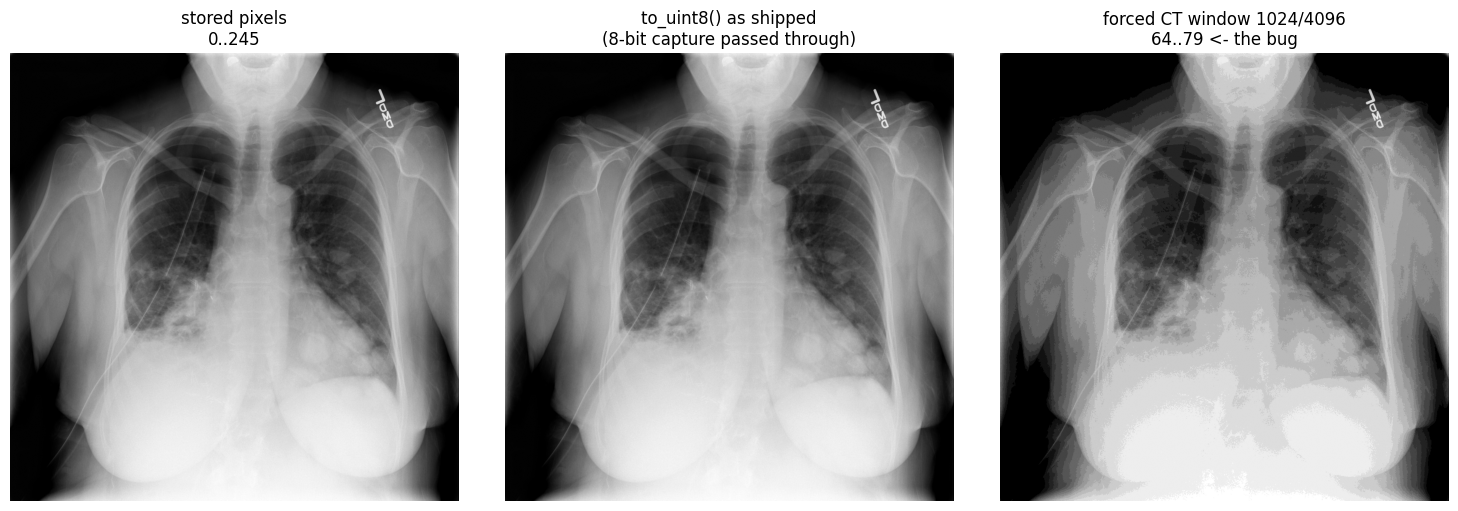

In [19]:
bad = to_uint8(ds, centre=WINDOW_CENTRE_DEFAULT, width=WINDOW_WIDTH_DEFAULT)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(raw, cmap="gray")
axes[0].set_title(f"stored pixels\n{int(raw.min())}..{int(raw.max())}")
axes[1].imshow(windowed, cmap="gray")
axes[1].set_title("to_uint8() as shipped\n(8-bit capture passed through)")
axes[2].imshow(bad, cmap="gray")
axes[2].set_title(f"forced CT window 1024/4096\n{int(bad.min())}..{int(bad.max())} <- the bug")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(REPO_ROOT / "results" / "plots" / "eda_windowing.png", dpi=130)
plt.show()

## 5 · Pixel intensity distribution, and the drift baseline

We sample a subset of images (reading 30k DICOM files is slow and adds nothing here), then compute the intensity
histogram overall and per class.

The training-split statistics are saved to `results/train_pixel_stats.json`. **Phase 4's drift monitor reads that
file** to decide whether incoming studies still look like the data the model was trained on. Note that it is
computed on the *train* split only — using test images to define the reference would be its own small leak.

In [20]:
N_SAMPLE = 600
sample = images.sample(n=min(N_SAMPLE, len(images)), random_state=7)
label_of = dict(zip(sample["dicom_path"], sample["label"]))
rel_of = dict(zip(sample["dicom_path"], sample["dicom_rel"]))

records = []
for path in sample["dicom_path"]:
    try:
        arr = to_uint8(read_study(path))
        records.append({
            "dicom_path": path,
            "dicom_rel": rel_of[path],
            "label": label_of[path],
            "mean": float(arr.mean()), "std": float(arr.std()),
            "p01": float(np.percentile(arr, 1)), "p50": float(np.percentile(arr, 50)),
            "p99": float(np.percentile(arr, 99)), "frac_near_black": float((arr < 8).mean()),
        })
    except Exception:
        continue

intensity = pd.DataFrame(records)
print(f"read {len(intensity):,} of {len(sample):,} sampled images")
intensity.describe().round(3)

read 600 of 600 sampled images


,label,mean,std,p01,p50,p99,frac_near_black
count,600.000,600.000,600.000,600.000,600.000,600.000,600.000
mean,0.233,125.273,57.878,4.910,130.917,217.435,0.057
std,0.423,21.475,10.935,9.744,26.914,22.027,0.056
min,0.000,50.101,23.092,0.000,8.000,143.000,0.000
25%,0.000,110.043,50.506,0.000,113.000,207.750,0.018
50%,0.000,120.750,59.263,1.000,125.000,224.000,0.044
75%,0.000,139.063,66.579,5.000,149.000,233.000,0.077
max,1.000,181.020,81.995,71.000,199.000,250.000,0.499


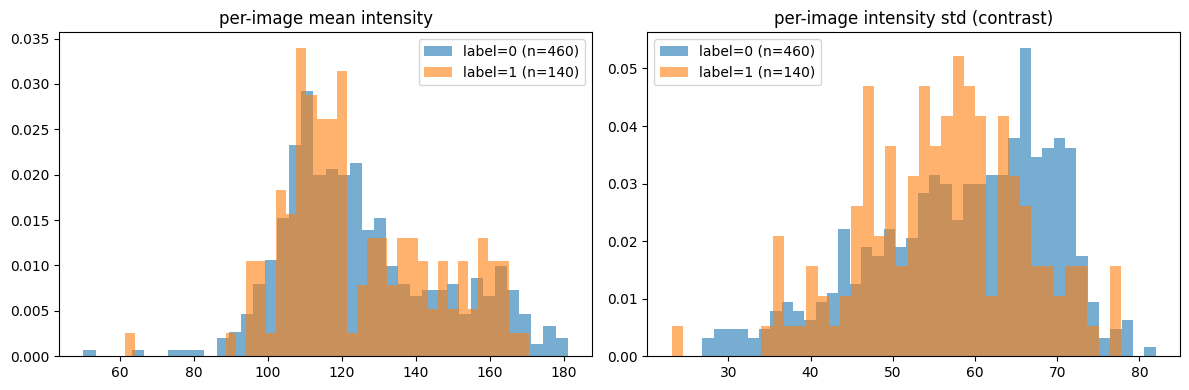

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for value, group in intensity.groupby("label"):
    axes[0].hist(group["mean"], bins=40, alpha=0.6, label=f"label={value} (n={len(group)})", density=True)
    axes[1].hist(group["std"], bins=40, alpha=0.6, label=f"label={value} (n={len(group)})", density=True)
axes[0].set_title("per-image mean intensity")
axes[1].set_title("per-image intensity std (contrast)")
axes[0].legend(); axes[1].legend()
fig.tight_layout()
fig.savefig(REPO_ROOT / "results" / "plots" / "eda_intensity.png", dpi=130)
plt.show()

## 6 — Leakage-safe split

Grouping on `patient_id`. In this release that resolves to one image per group (section 1 proved it), but the
split function is written for archives where it does not, and Phase 2 trains against these exact CSVs.

In [23]:
from src.data.splits import patient_level_split, assert_no_patient_leakage

train, val, test = patient_level_split(
    images, patient_col="patient_id", label_col="label",
    fractions=(0.70, 0.15, 0.15), seed=7,
)
assert_no_patient_leakage(train, val, test, patient_col="patient_id")
print("leakage check passed: no patient appears in more than one fold")

leakage check passed: no patient appears in more than one fold


In [24]:
summary = pd.DataFrame({
    "images": [len(train), len(val), len(test)],
    "groups": [f["patient_id"].nunique() for f in (train, val, test)],
    "pct_images": [len(f) / len(images) * 100 for f in (train, val, test)],
    "opacity_rate_pct": [f["label"].mean() * 100 for f in (train, val, test)],
    "mean_boxes": [f["n_boxes"].mean() for f in (train, val, test)],
}, index=["train", "val", "test"]).round(2)
print(summary)

print("\ntotal images:", f"{len(images):,}", "| sum of folds:", f"{len(train) + len(val) + len(test):,}")
assert len(train) + len(val) + len(test) == len(images), "a fold dropped rows"
assert set(train["dicom_path"]) & set(val["dicom_path"]) == set()
assert set(train["dicom_path"]) & set(test["dicom_path"]) == set()
print("assertions passed: folds are disjoint and complete")

       images  groups  pct_images  opacity_rate_pct  mean_boxes
train   18678   18678        70.0             22.53        0.36
val      4003    4003        15.0             22.53        0.36
test     4003    4003        15.0             22.53        0.36

total images: 26,684 | sum of folds: 26,684
assertions passed: folds are disjoint and complete


In [25]:
# Stratification balances the GROUP, not the row. On this release a group is one image, so the group-level
# and image-level rates coincide - on an archive with several films per patient they would not.
per_fold = pd.DataFrame({
    "images": [len(f) for f in (train, val, test)],
    "groups": [f["patient_id"].nunique() for f in (train, val, test)],
    "positive_groups": [f.drop_duplicates("patient_id")["label"].sum() for f in (train, val, test)],
}, index=["train", "val", "test"])
per_fold["group_prevalence_pct"] = (per_fold["positive_groups"] / per_fold["groups"] * 100).round(2)
print(per_fold)

overall = images.drop_duplicates("patient_id")["label"].mean() * 100
spread = per_fold["group_prevalence_pct"].max() - per_fold["group_prevalence_pct"].min()
smallest = int(per_fold["groups"].min())
print(f"\noverall group-level prevalence: {overall:.2f}%")
print(f"spread across folds           : {spread:.2f} percentage points (smallest fold has {smallest:,} groups)")
if smallest < 30:
    print("VERDICT: too few groups per fold to judge balance - a wide spread here is arithmetic, not a bug.")
elif spread < 2:
    print("VERDICT: acceptable. Stratified patient-level splitting is holding.")
else:
    print("VERDICT: REVIEW - the spread is larger than sampling noise explains. Check dominant-label assignment.")

print("\nSanity: a 1-image-per-group dataset makes group-level == image-level balance. Verify:")
print("  max images per group =", int(images.groupby("patient_id").size().max()))

       images  groups  positive_groups  group_prevalence_pct
train   18678   18678             4208                 22.53
val      4003    4003              902                 22.53
test     4003    4003              902                 22.53

overall group-level prevalence: 22.53%
spread across folds           : 0.00 percentage points (smallest fold has 4,003 groups)
VERDICT: acceptable. Stratified patient-level splitting is holding.

Sanity: a 1-image-per-group dataset makes group-level == image-level balance. Verify:


  max images per group = 1


## 7 · Persist everything the next phases need

In [26]:
results = REPO_ROOT / "results"
(results / "plots").mkdir(parents=True, exist_ok=True)

cols = [c for c in ["dicom_rel", "patient_id", "label", "n_boxes", "PatientSex", "age", "class"]
        if c in images]
train[cols].to_csv(results / "split_train.csv", index=False)
val[cols].to_csv(results / "split_val.csv", index=False)
test[cols].to_csv(results / "split_test.csv", index=False)

train_stats = train.merge(intensity.add_suffix("_i").rename(columns={"dicom_path_i": "dicom_path"}),
                          on="dicom_path", how="inner")
reference = {
    "n_images": int(len(train_stats)),
    "mean": {"mean": float(train_stats["mean_i"].mean()), "std": float(train_stats["mean_i"].std())},
    "std": {"mean": float(train_stats["std_i"].mean()), "std": float(train_stats["std_i"].std())},
    "computed_from": "train split only",
    "note": "reference distribution for the Phase 4 PSI drift monitor",
}
(results / "train_pixel_stats.json").write_text(json.dumps(reference, indent=2))

eda = {
    "dataset": "RSNA 2018 Pneumonia Detection Challenge, stage_2 release (label = lung opacity)",
    "label_file": LABELS_CSV.name,
    "data_dir": str(DATA_DIR),
    "images_dir": str(IMAGES_DIR),
    "path_base": str(DATA_DIR),
    "annotation_rows": int(len(ann)),
    "n_images": int(len(images)),
    "n_groups": int(images["patient_id"].nunique()),
    "images_per_group_max": int(images.groupby("patient_id").size().max()),
    "row_level_split_leak_pct": float(leak_pct),
    "opacity_prevalence_pct": float(images["label"].mean() * 100),
    "total_boxes": int(images["n_boxes"].sum()),
    "splits": {k: {"images": int(summary.loc[k, "images"]),
                   "groups": int(summary.loc[k, "groups"]),
                   "opacity_rate_pct": float(summary.loc[k, "opacity_rate_pct"])}
               for k in ["train", "val", "test"]},
    "dicom_tags": {
        "modality": (hdr["Modality"].value_counts().to_dict() if hdr is not None else None),
        "bits_allocated": (sorted(hdr["BitsAllocated"].dropna().unique().tolist()) if hdr is not None else None),
        "sex_populated": (int(hdr["PatientSex"].notna().sum()) if hdr is not None else None),
        "age_populated": (int(hdr["PatientAge"].notna().sum()) if hdr is not None else None),
        "patient_position_populated": (int(hdr["PatientPosition"].notna().sum()) if hdr is not None else None),
        "window_center_populated": (int(hdr["WindowCenter"].notna().sum()) if hdr is not None else None),
    },
    "demographics": {
        "sex_counts": images["PatientSex"].value_counts(dropna=False).to_dict() if "PatientSex" in images else None,
        "age_median": float(images["age"].median()) if "age" in images else None,
        "age_min": float(images["age"].min()) if "age" in images else None,
        "age_max": float(images["age"].max()) if "age" in images else None,
        "implausible_age_rows": (int(((images["age"] < 1) | (images["age"] > 110)).sum())
                                 if "age" in images else None),
    },
    "disclaimer": "For education only. Not for clinical use.",
}
(results / "eda_summary.json").write_text(json.dumps(eda, indent=2))
print(json.dumps(eda, indent=2))

{
  "dataset": "RSNA 2018 Pneumonia Detection Challenge, stage_2 release (label = lung opacity)",
  "label_file": "stage_2_train_labels.csv",
  "data_dir": "C:\\Users\\kumar\\Documents\\Qoder\\2026-10-22\\410be6bc\\AIML-02-medical-imaging\\data\\raw\\rsna",
  "images_dir": "C:\\Users\\kumar\\Documents\\Qoder\\2026-10-22\\410be6bc\\AIML-02-medical-imaging\\data\\raw\\rsna\\stage_2_train_images",
  "path_base": "C:\\Users\\kumar\\Documents\\Qoder\\2026-10-22\\410be6bc\\AIML-02-medical-imaging\\data\\raw\\rsna",
  "annotation_rows": 30227,
  "n_images": 26684,
  "n_groups": 26684,
  "images_per_group_max": 1,
  "row_level_split_leak_pct": 16.804498842209725,
  "opacity_prevalence_pct": 22.530355269075102,
  "total_boxes": 9555,
  "splits": {
    "train": {
      "images": 18678,
      "groups": 18678,
      "opacity_rate_pct": 22.53
    },
    "val": {
      "images": 4003,
      "groups": 4003,
      "opacity_rate_pct": 22.53
    },
    "test": {
      "images": 4003,
      "groups": 400

## 8 · Findings to paste into `docs/dataset_card.md`

Fill the `TODO`s in the dataset card from the output above. Do not carry over a number you did not produce here.

In [27]:
print(f"""### EDA findings (generated by notebooks/01_eda.ipynb)

- {eda['annotation_rows']:,} annotation rows describing **{eda['n_images']:,} DICOM images**. Every image
  resolves to exactly one file on disk; nothing was dropped.
- Envelope: Modality {eda['dicom_tags']['modality']}, {eda['dicom_tags']['bits_allocated']}-bit Secondary
  Capture, 1024x1024. `WindowCenter`, `PatientPosition` and `Manufacturer` are empty on all
  {eda['n_images']:,} files - the fingerprint of a converted image, not a scanner export.
- The label file is {eda['annotation_rows'] / eda['n_images']:.2f}x finer-grained than the image set (rows are
  bounding boxes). A row-level 70/30 split leaked **{eda['row_level_split_leak_pct']:.1f}%** of test rows; the
  image-level split leaked 0.
- De-identification assigned a unique `PatientID` per file ({eda['images_per_group_max']} image per group at
  most), so this release carries no recoverable multi-film patient structure.
- Prevalence: {eda['opacity_prevalence_pct']:.1f}% lung opacity, {eda['total_boxes']:,} boxes. A constant
  'no opacity' predictor scores {100 - eda['opacity_prevalence_pct']:.1f}% accuracy and finds nothing.
- Demographics for the fairness slice: sex on {eda['dicom_tags']['sex_populated']:,} files, age on
  {eda['dicom_tags']['age_populated']:,} (median {eda['demographics']['age_median']:.0f},
  range {eda['demographics']['age_min']:.0f}-{eda['demographics']['age_max']:.0f}).
  **{eda['demographics']['implausible_age_rows']:,} ages are outside 1-110 and are not trustworthy**; they are
  kept as images and excluded from age-band reporting.
- Train/val/test: {eda['splits']['train']['images']:,} / {eda['splits']['val']['images']:,} /
  {eda['splits']['test']['images']:,} images, all at {eda['splits']['train']['opacity_rate_pct']:.2f}% prevalence.
- Split CSVs store `dicom_rel`, resolved against `path_base` in `results/eda_summary.json`, so they still
  work when Phase 2 runs them on a different machine.
- Drift reference computed on the **train split only** -> results/train_pixel_stats.json
- For education only. Not for clinical use.
""")

### EDA findings (generated by notebooks/01_eda.ipynb)

- 30,227 annotation rows describing **26,684 DICOM images**. Every image
  resolves to exactly one file on disk; nothing was dropped.
- Envelope: Modality {'CR': 26684}, ['8']-bit Secondary
  Capture, 1024x1024. `WindowCenter`, `PatientPosition` and `Manufacturer` are empty on all
  26,684 files - the fingerprint of a converted image, not a scanner export.
- The label file is 1.13x finer-grained than the image set (rows are
  bounding boxes). A row-level 70/30 split leaked **16.8%** of test rows; the
  image-level split leaked 0.
- De-identification assigned a unique `PatientID` per file (1 image per group at
  most), so this release carries no recoverable multi-film patient structure.
- Prevalence: 22.5% lung opacity, 9,555 boxes. A constant
  'no opacity' predictor scores 77.5% accuracy and finds nothing.
- Demographics for the fairness slice: sex on 26,684 files, age on
  26,684 (median 49,
  range 1-155).
  **5 ages are outsid

## What this notebook proved

| Question | Answer | Course day |
|---|---|---|
| Is the data clean enough to model? | Section 1 audit — nulls, duplicates, and the rows-vs-images gap | 5, 6 |
| Does one row mean one picture? | **No.** 30,227 annotation rows / 26,684 images, measured | 6 |
| Would a random split leak? | Yes — 16.8% of test rows, measured in section 2 | 22 |
| Do I understand the image format? | Section 4 — envelope provenance and the 8-bit windowing bug | brief step 1 |
| Is the split trustworthy? | Section 6 — disjoint, complete, asserted | 22 |
| Can the model be monitored later? | Section 7 — drift baseline saved from train only | 28 |
| Can the model be audited for bias? | Section 3 — age and sex recovered for all 26,684 images | 24, brief step 7 |

**Three honest limits to carry into the report.** (1) "Lung opacity" is a radiographic *sign*, not a
diagnosis — the model flags whiteness a clinician then has to explain. (2) The 57% of negative images marked
"No Lung Opacity / Not Normal" are abnormal for other reasons, so the negative class is heterogeneous by
construction. (3) The pixels are an 8-bit display-encoded render, so the model never sees the original
detector dynamic range.

**Next:** `02_baseline_logreg.ipynb` — a logistic-regression floor on downsampled pixels, so the DenseNet
result in `03_train_densenet.ipynb` has something honest to be compared against.